In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd() / "../src"))


import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from prepare_data import test_ds

I0000 00:00:1792512412.076130  455736 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792512412.076519  455736 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792512412.116062  455736 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792512413.677262  455736 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

Found 17034 files belonging to 6 classes.
Using 11924 files for training.
Found 17034 files belonging to 6 classes.
Using 5110 files for validation.


E0000 00:00:1792512415.196795  455736 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [2]:
ROOT = Path.cwd().parent
MODEL_PATH = ROOT / "models" / "cnn_model.keras"
#MODEL_PATH = ROOT / "models" / "experiments" / "dropout_050.keras"

CLASSES = ["buildings", "forest", "glacier", "mountain", "sea", "street"]

In [3]:
model = tf.keras.models.load_model(MODEL_PATH)

In [4]:
image_batches = []
label_batches = []

for x, y in test_ds:
    image_batches.append(x.numpy())
    label_batches.append(y.numpy())

images = np.concatenate(image_batches)
y_true = np.concatenate(label_batches).reshape(-1)

In [5]:
y_pred = np.argmax(model.predict(images, verbose=0), axis=1)

In [6]:
print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(classification_report(
    y_true, y_pred, target_names=CLASSES, digits=4, zero_division=0
))

Accuracy: 0.8059
              precision    recall  f1-score   support

   buildings     0.7246    0.8231    0.7707       390
      forest     0.9409    0.9479    0.9444       403
     glacier     0.8338    0.6736    0.7452       432
    mountain     0.7875    0.7473    0.7669       471
         sea     0.7640    0.8565    0.8076       446
      street     0.8074    0.8015    0.8044       408

    accuracy                         0.8059      2550
   macro avg     0.8097    0.8083    0.8065      2550
weighted avg     0.8090    0.8059    0.8050      2550



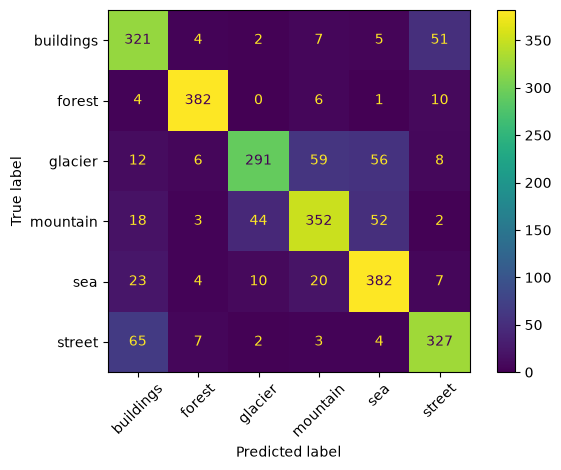

In [7]:
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm, display_labels=CLASSES)
disp.plot(xticks_rotation=45, values_format="d")
plt.tight_layout()
plt.show()
plt.close()


In [8]:
print("\nMost frequent confusions:")
errors = [
    (cm[i, j], CLASSES[i], CLASSES[j])
    for i in range(len(CLASSES))
    for j in range(len(CLASSES))
    if i != j and cm[i, j] > 0
]

for count, true_class, pred_class in sorted(errors, reverse=True)[:10]:
    print(f"{true_class} predicted as {pred_class}: {count}")



Most frequent confusions:
street predicted as buildings: 65
glacier predicted as mountain: 59
glacier predicted as sea: 56
mountain predicted as sea: 52
buildings predicted as street: 51
mountain predicted as glacier: 44
sea predicted as buildings: 23
sea predicted as mountain: 20
mountain predicted as buildings: 18
glacier predicted as buildings: 12


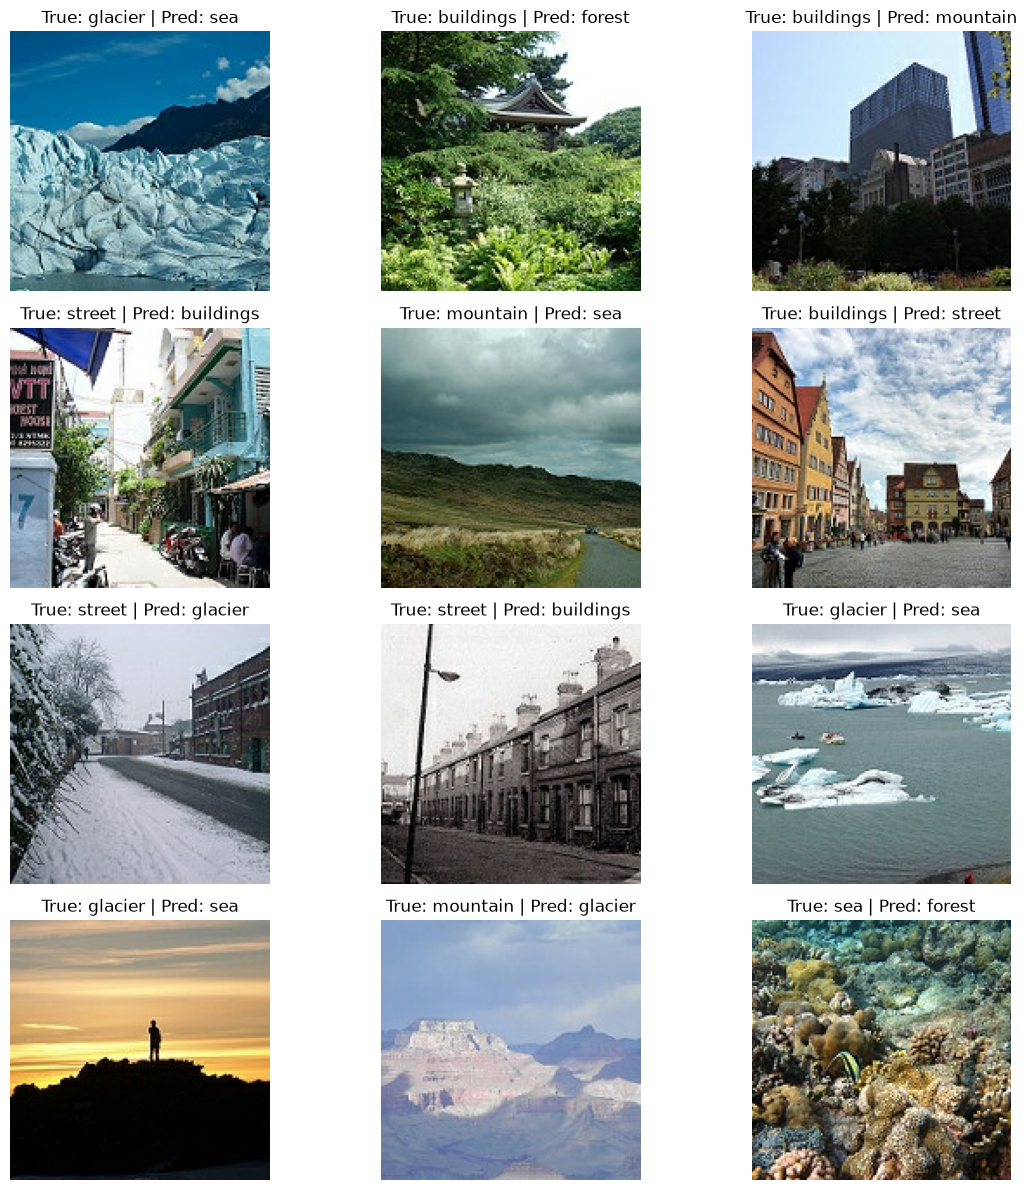

In [9]:
wrong = np.where(y_true != y_pred)[0][:12]

if len(wrong):
    fig, axes = plt.subplots(4, 3, figsize=(12, 12))

    for ax in axes.flat:
        ax.axis("off")

    for ax, i in zip(axes.flat, wrong):
        ax.imshow(np.clip(images[i], 0, 1))
        ax.set_title(f"True: {CLASSES[int(y_true[i])]} | Pred: {CLASSES[y_pred[i]]}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    plt.close(fig)